# 07 – FT-Transformer (transformer for tabular data)

Transformers were built for sequences of words. The **FT-Transformer** (*Feature Tokenizer + Transformer*,
Gorishniy et al., 2021) applies the same idea to a table row by treating **each feature as a "word" (token)**:

```
song row:  log_followers=2.1   year=-0.3   album_name_te=1.7   ...   genres=[pop, rap]
              │                  │              │                       │
   Feature    ▼                  ▼              ▼                       ▼
   Tokenizer  token_1            token_2        token_3        ...      genre token      (+ 1 extra [CLS] token)
              └──────────────────┴──────────────┴──────────────────────┘
                                   │
   Transformer        self-attention: every token looks at every other token
   (3 layers)         -> learns interactions like "many followers AND pop genre"
                                   │
   Head               the [CLS] token's final vector -> one number -> sigmoid -> P(hit)
```

- **Numeric feature → token:** `token_j = x_j · w_j + b_j`, where `w_j`, `b_j` are learned vectors of size 32.
  Each feature gets its own embedding direction, scaled by its value.
- **Genres → one token:** instead of 150 separate genre tokens, the 150 genre 0/1 columns are mapped to a single token
  through one linear layer (a "bag of genres" embedding). That keeps the sequence short and training fast.
- **[CLS] token:** an extra learned token with no input value. It collects information from all others through attention,
  and its final state is used for the prediction (the same trick as in BERT).

Preprocessing is the same as for logistic regression: neural networks need **no NaN** and **standardized inputs**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_features, compare_to_baseline, save_predictions

# same plot style as in the other notebooks
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# data + features from features.py (target encodings learned on dev only)
dev, valid, test, X_dev, X_valid, X_test = load_features()
y_dev, y_valid = dev["music_hit"], valid["music_hit"]
print("X_dev:", X_dev.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)

import time
import torch
import torch.nn as nn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

torch.manual_seed(42)  # reproducible weight initialisation
np.random.seed(42)     # reproducible batch order

# use the Mac's GPU (Apple 'mps') if available, otherwise the CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

X_dev: (280040, 191) | X_valid: (70011, 191) | X_test: (87513, 191)


device: mps


## 1. Preprocessing
- Split the columns into the 150 **genre 0/1 columns** (→ one genre token) and the **other columns** (→ one token each).
- Other columns: `log1p` on the song counts, fill NaN with the median + "missing" flags, standardize.
- For early stopping we hold out **fold 0 of dev**. The preprocessing is fitted on the remaining 4 folds.

In [2]:
genre_cols = [c for c in X_dev.columns if c.startswith("genre_") and not c.startswith("genre_te")]
num_cols = [c for c in X_dev.columns if c not in genre_cols]
count_cols = [c for c in num_cols if c.endswith("_n_songs")]

def log_counts(X):
    X = X.copy()
    X[count_cols] = np.log1p(X[count_cols])
    return X

# dev fold 0 = early-stopping set, folds 1-4 = training set
is_early = (dev["fold"] == 0).values
train_idx = np.where(~is_early)[0]

# fill NaN + add 'missing' columns, then standardize; fitted on the training folds only
prep = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
prep.fit(log_counts(X_dev[num_cols])[~is_early])

def to_tensors(X):
    """DataFrame -> (numeric tensor, genre tensor) for the network."""
    numeric = prep.transform(log_counts(X[num_cols]))
    return (torch.tensor(numeric, dtype=torch.float32),
            torch.tensor(X[genre_cols].values, dtype=torch.float32))

dev_num, dev_genre = to_tensors(X_dev)
valid_num, valid_genre = to_tensors(X_valid)
test_num, test_genre = to_tensors(X_test)
y_dev_t = torch.tensor(y_dev.values, dtype=torch.float32)

print("numeric tokens:", dev_num.shape[1], "| genre columns -> 1 token:", dev_genre.shape[1])

numeric tokens: 45 | genre columns -> 1 token: 150


## 2. The model
The whole architecture in about 30 lines. `nn.TransformerEncoderLayer` is PyTorch's standard transformer block
(self-attention + small feed-forward network, each with layer normalisation and a residual connection).

In [3]:
class FTTransformer(nn.Module):
    def __init__(self, n_numeric, n_genres, d=32, n_layers=3, n_heads=4, dropout=0.1):
        super().__init__()
        # feature tokenizer: one learned vector w_j and bias b_j (size d) per numeric feature
        self.num_weight = nn.Parameter(torch.randn(n_numeric, d) * 0.1)
        self.num_bias = nn.Parameter(torch.zeros(n_numeric, d))
        # all genre 0/1 columns -> one token of size d
        self.genre_token = nn.Linear(n_genres, d)
        # the extra [CLS] token whose output is used for the prediction
        self.cls_token = nn.Parameter(torch.randn(1, 1, d) * 0.1)

        # stack of standard transformer blocks
        block = nn.TransformerEncoderLayer(d_model=d, nhead=n_heads, dim_feedforward=2 * d,
                                           dropout=dropout, batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(block, num_layers=n_layers, enable_nested_tensor=False)

        # prediction head: [CLS] vector -> one number (the log-odds of 'hit')
        self.head = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 1))

    def forward(self, x_num, x_genre):
        batch_size = x_num.shape[0]
        # (batch, n_numeric, 1) * (n_numeric, d) -> (batch, n_numeric, d): one token per feature
        num_tokens = x_num.unsqueeze(-1) * self.num_weight + self.num_bias
        genre_token = self.genre_token(x_genre).unsqueeze(1)            # (batch, 1, d)
        cls = self.cls_token.expand(batch_size, -1, -1)                 # (batch, 1, d)

        tokens = torch.cat([cls, num_tokens, genre_token], dim=1)       # the 'sentence' for this song
        out = self.transformer(tokens)
        return self.head(out[:, 0]).squeeze(-1)                         # read out the [CLS] position

model = FTTransformer(n_numeric=dev_num.shape[1], n_genres=dev_genre.shape[1]).to(device)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

trainable parameters: 33,473


## 3. Training
- **Loss:** binary cross-entropy (`BCEWithLogitsLoss` applies the sigmoid itself)
- **Optimizer:** AdamW, learning rate 0.001
- **Mini-batches** of 1,024 songs, reshuffled every epoch
- **Early stopping:** after every epoch, compute the AUC on dev fold 0. Stop when it hasn't improved for 3 epochs and keep the best weights.

In [4]:
def predict(x_num, x_genre, batch_size=4096):
    """Hit probabilities for many songs, computed in batches."""
    model.eval()                      # turns dropout off
    preds = []
    with torch.no_grad():             # no gradients needed for prediction
        for i in range(0, len(x_num), batch_size):
            logits = model(x_num[i:i + batch_size].to(device), x_genre[i:i + batch_size].to(device))
            preds.append(torch.sigmoid(logits).cpu())
    return torch.cat(preds).numpy()

loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)

BATCH_SIZE, MAX_EPOCHS, PATIENCE = 1024, 20, 3
history, best_auc, best_state, epochs_without_improvement = [], 0, None, 0

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()
    model.train()                                             # turns dropout on
    shuffled = np.random.permutation(train_idx)
    for i in range(0, len(shuffled), BATCH_SIZE):
        batch = shuffled[i:i + BATCH_SIZE]
        logits = model(dev_num[batch].to(device), dev_genre[batch].to(device))
        loss = loss_fn(logits, y_dev_t[batch].to(device))
        optimizer.zero_grad()   # reset gradients from the previous batch
        loss.backward()         # backpropagation: compute gradients
        optimizer.step()        # update the weights

    # score on the early-stopping set
    auc_early = roc_auc_score(y_dev.values[is_early], predict(dev_num[is_early], dev_genre[is_early]))
    history.append(auc_early)
    print(f"epoch {epoch:2d}  early-stopping AUC {auc_early:.4f}  ({time.time() - start:.0f} s)")

    if auc_early > best_auc:      # new best -> remember these weights
        best_auc, epochs_without_improvement = auc_early, 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"no improvement for {PATIENCE} epochs -> stop")
            break

model.load_state_dict(best_state)  # go back to the best epoch

/var/folders/yn/l15r01r12s5g0hv3psd2rxg00000gn/T/ipykernel_58308/3211047350.py:30: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  auc_early = roc_auc_score(y_dev.values[is_early], predict(dev_num[is_early], dev_genre[is_early]))


epoch  1  early-stopping AUC 0.9570  (22 s)


epoch  2  early-stopping AUC 0.9619  (21 s)


epoch  3  early-stopping AUC 0.9629  (21 s)


epoch  4  early-stopping AUC 0.9641  (21 s)


epoch  5  early-stopping AUC 0.9644  (21 s)


... (7 outputs left out)

epoch 13  early-stopping AUC 0.9656  (23 s)


epoch 14  early-stopping AUC 0.9656  (23 s)


epoch 15  early-stopping AUC 0.9660  (26 s)
no improvement for 3 epochs -> stop


<All keys matched successfully>

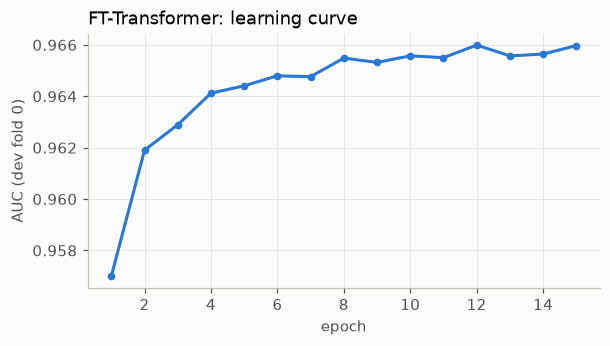

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, len(history) + 1), history, color=BLUE, lw=2, marker="o", ms=4)
ax.set_xlabel("epoch"); ax.set_ylabel("AUC (dev fold 0)")
ax.set_title("FT-Transformer: learning curve", loc="left")
plt.show()

## 4. Validation AUC vs. baseline

In [6]:
valid_pred = predict(valid_num, valid_genre)
auc = compare_to_baseline("FT-Transformer", y_valid, valid_pred)

FT-Transformer: validation AUC = 0.9677
baseline (artist_followers alone)  = 0.8747
improvement                        = +0.0930


**Interpretation.** The transformer clearly beats the baseline. On tabular data like this, gradient-boosted trees
are usually hard to beat, and the result here is in the same range. Its real value is in the ensemble:
a neural network makes **different mistakes** than tree models, so averaging them can help (notebook 08).

In [7]:
test_pred = predict(test_num, test_genre)
save_predictions("ft_transformer", valid, valid_pred, test, test_pred)